In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Load Libraries

In [ ]:
import pandas as pd
import numpy as np
import torch
import os
import matplotlib.pyplot as plt


# Load Cleaned dataset

In [ ]:
DATA_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Data/Assamese_Movie_Review_Cleaned_8987.csv"

df = pd.read_csv(DATA_PATH)
df.head()


,ID,Reviews,Sentiment
0,0,বোকা নাটক,negative
1,1,নাটকখন বৰ ধুনীয়া আছিল,positive
2,2,এখন ভাল ঘৰ এনে হব লাগে,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive
4,4,মই বহুদিন অপেক্ষা কৰি আছো. অৱশেষত দেখিলো. কেৱল...,positive


# Remove Corrupted Row

In [ ]:
# Remove corrupted row with header leakage
df = df[~((df['ID'] == 4227) & (df['Reviews'] == 'Reviews'))].reset_index(drop=True)

print("Dataset shape after removing corrupted row:", df.shape)


Dataset shape after removing corrupted row: (8986, 3)


In [ ]:
assert not ((df['Reviews'] == 'Reviews') | (df['Sentiment'].isna())).any(), \
    "Corrupted rows still exist in the dataset"


# Encode Sentiment Labels

In [ ]:
df['Sentiment'] = (
    df['Sentiment']
    .astype(str)
    .str.strip()
    .str.lower()
)

label_map = {'negative': 0, 'positive': 1}
df['label'] = df['Sentiment'].map(label_map)

df = df.dropna(subset=['label']).reset_index(drop=True)

assert df['label'].isna().sum() == 0


# Pre-Tokenization Normalization

In [ ]:
# Ensure all reviews are strings (critical for tokenizers)
df['Reviews'] = df['Reviews'].astype(str)

# Remove empty or whitespace-only reviews
df = df[df['Reviews'].str.strip() != ""].reset_index(drop=True)

# Sanity checks
assert df['Reviews'].isna().sum() == 0, "NaN found in Reviews"
assert df['label'].isna().sum() == 0, "NaN found in labels"

print("Pre-tokenization normalization completed")
print("Dataset shape:", df.shape)


Pre-tokenization normalization completed
Dataset shape: (8986, 4)


# Train-Test-Validation Split

In [ ]:
from sklearn.model_selection import train_test_split

texts = df['Reviews'].values.tolist()
labels = df['label'].values.tolist()

train_texts, val_texts, train_labels, val_labels = train_test_split(
    texts,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

len(train_texts), len(val_texts)

(7188, 1798)

# IndicBERT Tokenizer

In [ ]:
from huggingface_hub import login
login()


In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "ai4bharat/indic-bert"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


config.json:   0%|          | 0.00/507 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/5.65M [00:00<?, ?B/s]

# Tokenize Function

In [ ]:
train_encodings = tokenizer(
    train_texts,
    truncation=True,
    padding=True,
    max_length=256
)

val_encodings = tokenizer(
    val_texts,
    truncation=True,
    padding=True,
    max_length=256
)


# Dataset Class

In [ ]:
class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)


In [ ]:
train_dataset = SentimentDataset(train_encodings, train_labels)
val_dataset = SentimentDataset(val_encodings, val_labels)


# Model Loading

In [ ]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)


pytorch_model.bin:   0%|          | 0.00/135M [00:00<?, ?B/s]

Some weights of AlbertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/indic-bert and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


# Training Hyperparameters

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./results_indicbert",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,          # Slightly higher than MuRIL
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=5,          # IndicBERT benefits from 1 extra epoch
    weight_decay=0.01,
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    report_to="none"
)


# Metrics Function

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro"
    )
    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    }


# Trainer

In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)


In [ ]:
trainer.train()


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,0.387200,0.302311,0.880423,0.875576,0.865031,0.869736
2,0.225000,0.248720,0.917130,0.906921,0.920553,0.912514
3,0.173400,0.287590,0.919355,0.909006,0.924204,0.915044
4,0.098400,0.314591,0.927141,0.920584,0.923433,0.921967
5,0.049500,0.356700,0.924360,0.918501,0.919026,0.918762


TrainOutput(global_step=2250, training_loss=0.20606622091929117, metrics={'train_runtime': 1497.9189, 'train_samples_per_second': 23.993, 'train_steps_per_second': 1.502, 'total_flos': 429448888627200.0, 'train_loss': 0.20606622091929117, 'epoch': 5.0})

In [ ]:
eval_results = trainer.evaluate()
eval_results


{'eval_loss': 0.31459149718284607,
 'eval_accuracy': 0.9271412680756396,
 'eval_macro_precision': 0.9205844477464091,
 'eval_macro_recall': 0.9234327794561934,
 'eval_macro_f1': 0.921966847058161,
 'eval_runtime': 23.3566,
 'eval_samples_per_second': 76.981,
 'eval_steps_per_second': 4.838,
 'epoch': 5.0}

# EVALUATION & VISUALIZATIONS

In [ ]:
CONF_MATRIX_DIR = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/Confusion Matrix/"
RESULTS_DIR = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/"

os.makedirs(CONF_MATRIX_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)


# Predictions

In [ ]:
import scipy as sp
from scipy.special import softmax

predictions = trainer.predict(val_dataset)

y_true = predictions.label_ids
y_logits = predictions.predictions
y_pred = np.argmax(y_logits, axis=1)
y_probs = softmax(y_logits, axis=1)[:, 1]

# Confusion Matrix

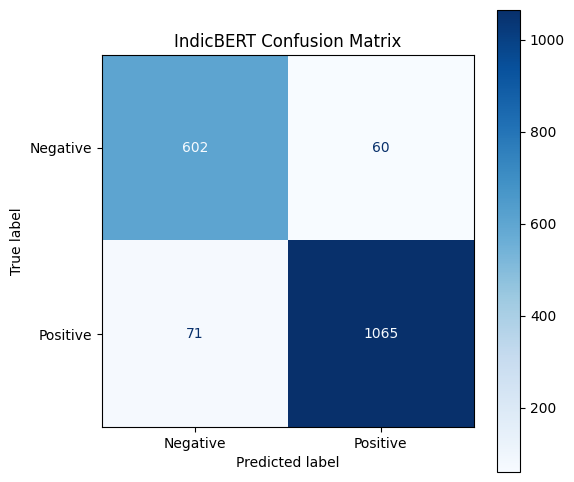

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"])
disp.plot(ax=ax, cmap="Blues", values_format="d")

ax.set_title("IndicBERT Confusion Matrix")

cm_path = os.path.join(CONF_MATRIX_DIR, "indicbert_confusion_matrix.svg")
plt.savefig(cm_path, format="svg", bbox_inches="tight")
plt.show()


# ROC-AUC Curve

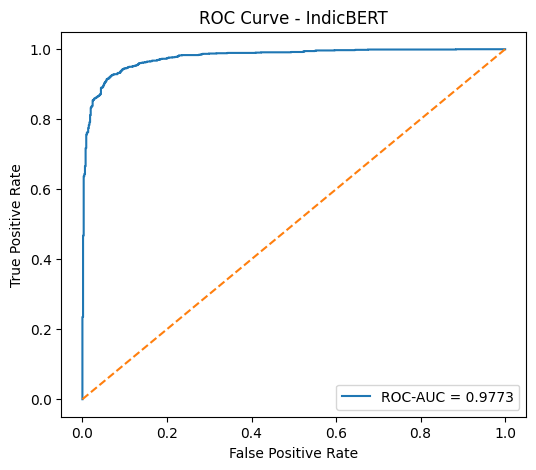

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve

roc_auc = roc_auc_score(y_true, y_probs)
fpr, tpr, _ = roc_curve(y_true, y_probs)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
ax.plot([0,1], [0,1], linestyle="--")

ax.set_title("ROC Curve - IndicBERT")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()

roc_path = os.path.join(RESULTS_DIR, "indicbert_roc_curve.svg")
plt.savefig(roc_path, format="svg", bbox_inches="tight")
plt.show()


# Training vs Validation Loss Curve

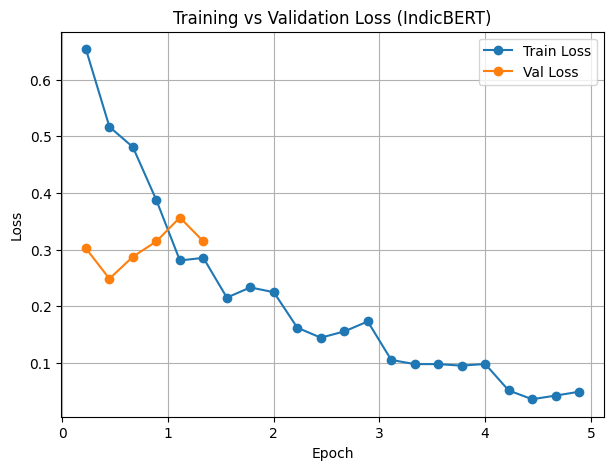

In [ ]:
train_loss, eval_loss, epochs = [], [], []

for log in trainer.state.log_history:
    if "loss" in log and "epoch" in log:
        train_loss.append(log["loss"])
        epochs.append(log["epoch"])
    if "eval_loss" in log:
        eval_loss.append(log["eval_loss"])

fig, ax = plt.subplots(figsize=(7,5))
ax.plot(epochs[:len(train_loss)], train_loss, label="Train Loss", marker="o")
ax.plot(epochs[:len(eval_loss)], eval_loss, label="Val Loss", marker="o")

ax.set_title("Training vs Validation Loss (IndicBERT)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(True)

loss_path = os.path.join(RESULTS_DIR, "indicbert_training_validation_loss.svg")
plt.savefig(loss_path, format="svg", bbox_inches="tight")
plt.show()


Cohen's Kappa

In [ ]:
from sklearn.metrics import cohen_kappa_score

kappa = cohen_kappa_score(y_true, y_pred)

print("Cohen's Kappa:", kappa)


Cohen's Kappa: 0.8439399500953436


# Final Evaluation Scores

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score

indicbert_results = {
    "Model": "IndicBERT",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro Precision": precision_score(y_true, y_pred, average="macro"),
    "Macro Recall": recall_score(y_true, y_pred, average="macro"),
    "Macro F1": f1_score(y_true, y_pred, average="macro"),
    "ROC-AUC": roc_auc,
    "Cohen's Kappa": cohen_kappa_score(y_true, y_pred)
}

table = pd.DataFrame([indicbert_results])
table

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,ROC-AUC,Cohen's Kappa
0,IndicBERT,0.927141,0.920584,0.923433,0.921967,0.977318,0.84394


In [43]:
MODEL_SAVE_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Models/indicBERT/indicbert-finetuned"

os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

print("Model directory ready:", MODEL_SAVE_PATH)


Model directory ready: /content/drive/MyDrive/Assamese_Sentiment_Analysis/Models/indicBERT/indicbert-finetuned


In [44]:
trainer.save_model(MODEL_SAVE_PATH)
tokenizer.save_pretrained(MODEL_SAVE_PATH)

print("MuRIL fine-tuned model saved at:")
print(MODEL_SAVE_PATH)


MuRIL fine-tuned model saved at:
/content/drive/MyDrive/Assamese_Sentiment_Analysis/Models/indicBERT/indicbert-finetuned
